## Environment Information

- **Execution Environment:** Google Colab
- **Python:** 3.13.16
- **pandas:** 2.2.3
- **matplotlib:** 3.10.0
- **scipy:** 1.16.3
- **statsmodels:** 0.15.0

## setting up

In [37]:
#package
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col

In [36]:
#set current directrory
# os.chdir("")

In [5]:
#read data
df = pd.read_stata("data/maketable4.dta")

In [6]:
df.columns

Index(['shortnam', 'africa', 'lat_abst', 'rich4', 'avexpr', 'logpgp95',
       'logem4', 'asia', 'loghjypl', 'baseco'],
      dtype='object')

In [24]:
df['baseco'].value_counts(dropna = False)

,count
baseco,
NaN,99
1.0,64


In [26]:
#restrict beseco =1
df = df[df["baseco"] == 1].copy()

## A1

### Report N, mean, and standard deviation for the three specified variables.

In [27]:
#create tabele
df_a = df.loc[
    (df["baseco"] == 1),
].dropna(subset=["avexpr", "logem4", "logpgp95", "lat_abst"])

summary = (
    df_a[["avexpr", "logpgp95", "logem4"]]
    .agg(["count", "mean", "std"])
    .T
    .rename(columns={"count": "N", "mean": "Mean", "std": "STD"})
)

summary.index.name = "Variables"

display(summary)

,N,Mean,STD
Variables,,,
avexpr,64.0,6.515625,1.468647
logpgp95,64.0,8.062237,1.043359
logem4,64.0,4.657031,1.257983


In [28]:
#transrate tabele for latex
latex_table = summary.to_latex(
    index=True,
    float_format="%.3f",
    column_format="lrrr",
    caption="Descriptive Statistics",
    label="tab:descriptive_statistics"
)

print(latex_table)

\begin{table}
\caption{Descriptive Statistics}
\label{tab:descriptive_statistics}
\begin{tabular}{lrrr}
\toprule
 & N & Mean & STD \\
Variables &  &  &  \\
\midrule
avexpr & 64.000 & 6.516 & 1.469 \\
logpgp95 & 64.000 & 8.062 & 1.043 \\
logem4 & 64.000 & 4.657 & 1.258 \\
\bottomrule
\end{tabular}
\end{table}



### Plot avexpr against logem4 in a scatter plot.

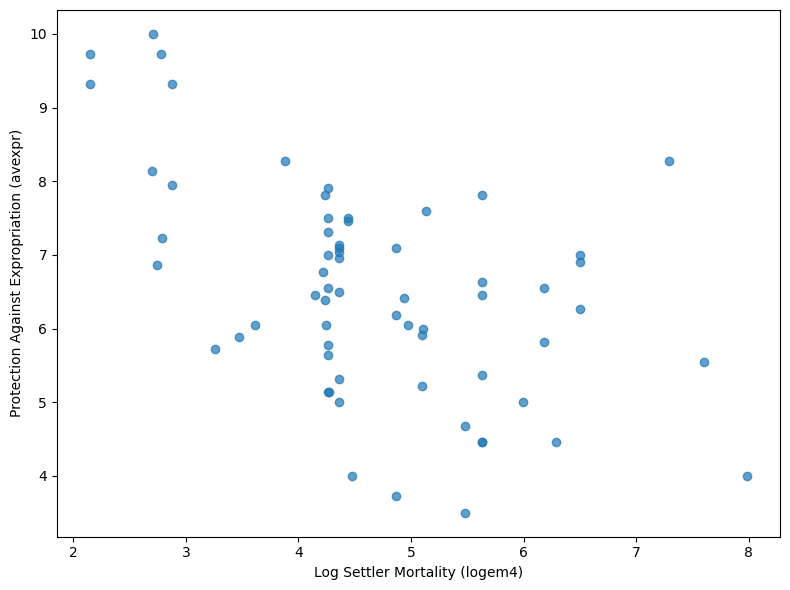

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    df_a["logem4"],
    df_a["avexpr"],
    alpha=0.7
)

ax.set_xlabel("Log Settler Mortality (logem4)")
ax.set_ylabel("Protection Against Expropriation (avexpr)")

plt.tight_layout()
plt.show()

### Describe the relationship between the two variables in one sentence.

In [30]:
#calculate correlation
r, p_value = pearsonr(df_a["logem4"], df_a["avexpr"])

print(f"Pearson correlation: {r:.3f}")
print(f"P-value: {p_value:.4f}")

Pearson correlation: -0.520
P-value: 0.0000


## A2

### Estimate two OLS models with heteroskedasticity-robust standard errors and report coefficients, standard errors, N, and R² in a two-column table.

In [31]:
# OLS with HC1 STD error

# Model 1
model1 = smf.ols(
    "avexpr ~ logem4",
    data=df_a
).fit(cov_type="HC1")

# Model 2
model2 = smf.ols(
    "avexpr ~ logem4 + lat_abst",
    data=df_a
).fit(cov_type="HC1")

# results
for model in [model1, model2]:
    print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 avexpr   R-squared:                       0.270
Model:                            OLS   Adj. R-squared:                  0.258
Method:                 Least Squares   F-statistic:                     16.32
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           0.000150
Time:                        02:21:56   Log-Likelihood:                -104.83
No. Observations:                  64   AIC:                             213.7
Df Residuals:                      62   BIC:                             218.0
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.3414      0.704     13.264      0.0

In [32]:
#transrate tabele for latex
reg_table = summary_col(
    [model1, model2],
    model_names=["Model 1", "Model 2"],
    stars=False,
    float_format="%.3f",
    info_dict={
        "N": lambda x: f"{int(x.nobs)}"
    },
    regressor_order=["Intercept", "logem4", "lat_abst"]
)

latex_table = reg_table.as_latex()

latex_table = latex_table.replace(
    "Standard errors in parentheses.",
    "HC1 heteroskedasticity-robust standard errors in parentheses."
)

print(latex_table)

\begin{table}
\caption{}
\label{}
\begin{center}
\begin{tabular}{lll}
\hline
               & Model 1 & Model 2  \\
\hline
Intercept      & 9.341   & 8.529    \\
               & (0.704) & (0.921)  \\
logem4         & -0.607  & -0.510   \\
               & (0.150) & (0.165)  \\
lat\_abst      &         & 2.002    \\
               &         & (1.369)  \\
R-squared      & 0.270   & 0.296    \\
R-squared Adj. & 0.258   & 0.273    \\
N              & 64      & 64       \\
\hline
\end{tabular}
\end{center}
\end{table}
\bigskip
HC1 heteroskedasticity-robust standard errors in parentheses.


## A3

### Report the country code, observed outcome, fitted value, and residual for the first five observations in Model 2, preserving the dataset's current order.

In [33]:
#report fittedvalue and residuals in head 5 country
a3_table = df_a[["shortnam", "avexpr"]].copy()

a3_table["Fitted value"] = model2.fittedvalues
a3_table["Residual"] = model2.resid

print(a3_table.head(5).to_string(index=False, float_format="%.3f"))

shortnam  avexpr  Fitted value  Residual
     AGO   5.364         5.928    -0.564
     ARG   6.386         7.126    -0.740
     AUS   9.318         8.035     1.283
     BFA   4.455         5.943    -1.489
     BGD   5.136         6.885    -1.749


In [34]:
# Report fitted values and residuals for the first 5 countries
a3_table = df_a[["shortnam", "avexpr"]].copy()

a3_table["Fitted value"] = model2.fittedvalues
a3_table["Residual"] = model2.resid

latex_table = a3_table.head(5).to_latex(
    index=False,
    float_format="%.3f",
    caption="Fitted Values and Residuals (Model 2)",
    label="tab:fitted_residuals"
)

print(latex_table)

\begin{table}
\caption{Fitted Values and Residuals (Model 2)}
\label{tab:fitted_residuals}
\begin{tabular}{lrrr}
\toprule
shortnam & avexpr & Fitted value & Residual \\
\midrule
AGO & 5.364 & 5.928 & -0.564 \\
ARG & 6.386 & 7.126 & -0.740 \\
AUS & 9.318 & 8.035 & 1.283 \\
BFA & 4.455 & 5.943 & -1.489 \\
BGD & 5.136 & 6.885 & -1.749 \\
\bottomrule
\end{tabular}
\end{table}



### Report the mean residual over the entire estimation sample

In [35]:
print(f"Mean residual: {model2.resid.mean():.6f}")

Mean residual: 0.000000
